Step 1 — Import libraries and configure the dataset

In [3]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices("GPU"))
print("Libraries imported successfully!")

TensorFlow Version: 2.15.1
GPU Available: []
Libraries imported successfully!


In [10]:
# ==========================================
# 2. DATASET CONFIGURATION
# ==========================================

PROJECT_DIR = os.path.dirname(os.getcwd())

DATASET_DIR = os.path.join(
    PROJECT_DIR,
    "datasets",
    "roboflow-pig-weight"
)

TRAIN_DIR = os.path.join(DATASET_DIR, "train")
VALID_DIR = os.path.join(DATASET_DIR, "valid")
TEST_DIR = os.path.join(DATASET_DIR, "test")

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

print("Project Directory:", PROJECT_DIR)
print("Dataset Directory:", DATASET_DIR)

print("\nDataset Folder Verification:")
print("Training:", os.path.isdir(TRAIN_DIR))
print("Validation:", os.path.isdir(VALID_DIR))
print("Testing:", os.path.isdir(TEST_DIR))

assert os.path.isdir(TRAIN_DIR), "Training directory not found!"
assert os.path.isdir(VALID_DIR), "Validation directory not found!"
assert os.path.isdir(TEST_DIR), "Testing directory not found!"

print("\nAll dataset directories exist!")

Project Directory: d:\CapstonePrototype\smart-pig-farm
Dataset Directory: d:\CapstonePrototype\smart-pig-farm\datasets\roboflow-pig-weight

Dataset Folder Verification:
Training: True
Validation: True
Testing: True

All dataset directories exist!


In [9]:
# ==========================================
# 3. LOAD IMAGE DATASETS
# ==========================================

train_dataset = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

valid_dataset = keras.utils.image_dataset_from_directory(
    VALID_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_dataset = keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_dataset.class_names
NUM_CLASSES = len(class_names)

print("\nWeight Categories:")
print(class_names)

print("\nNumber of Classes:", NUM_CLASSES)

Found 601 files belonging to 9 classes.
Found 75 files belonging to 9 classes.
Found 77 files belonging to 9 classes.

Weight Categories:
['100kg', '120kg', '150kg', '192kg', '31kg', '33kg', '50kg', '73kg', '95kg']

Number of Classes: 9


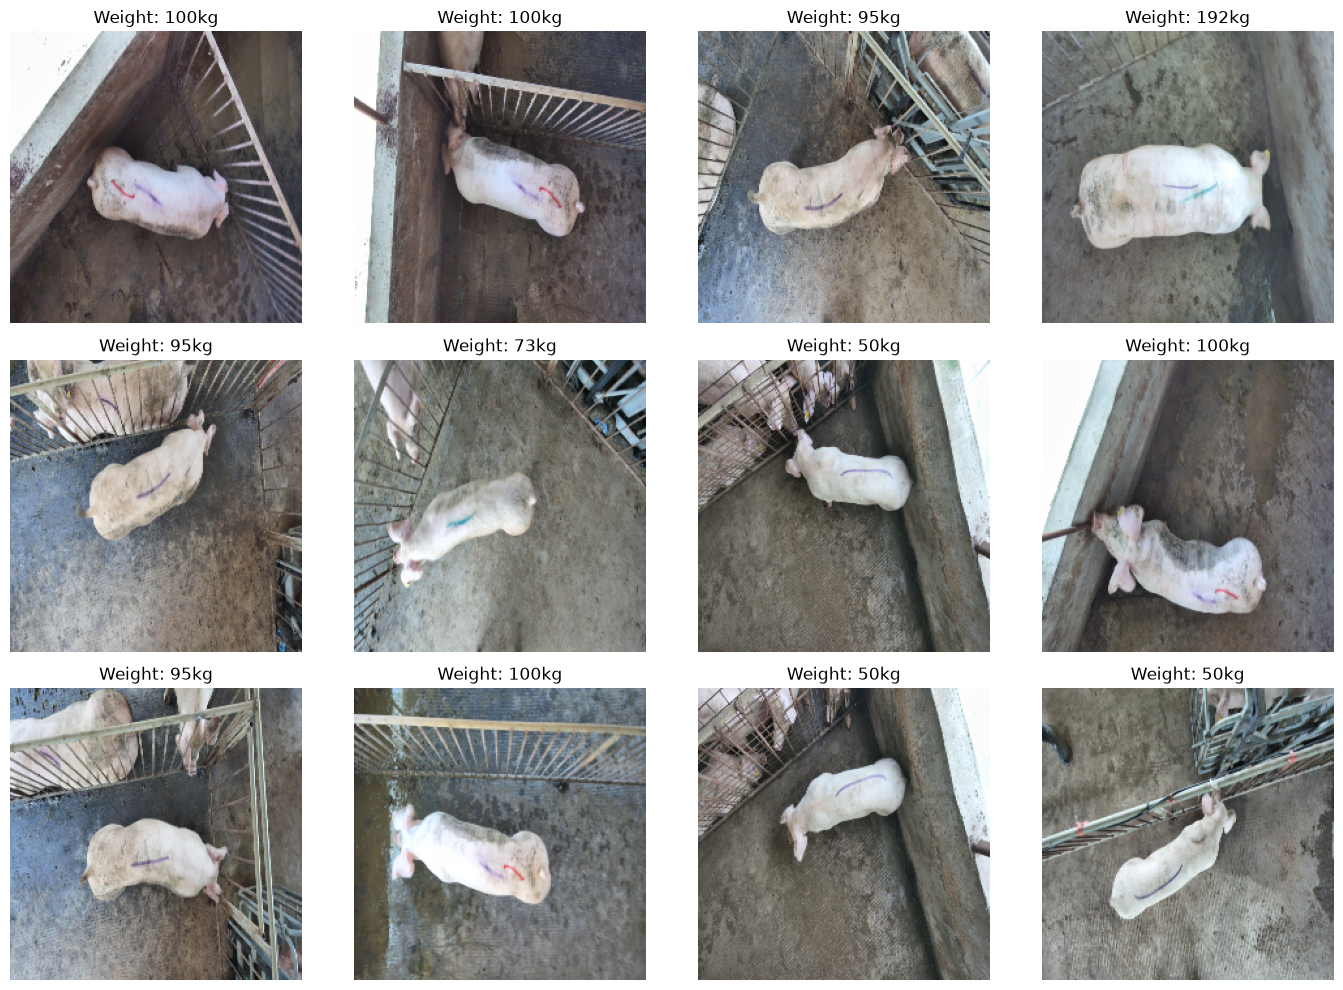

In [11]:
# ==========================================
# 4. VISUALIZE SAMPLE PIG IMAGES
# ==========================================

plt.figure(figsize=(14, 10))

for images, labels in train_dataset.take(1):
    for i in range(min(12, len(images))):
        plt.subplot(3, 4, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label = class_names[labels[i].numpy()]

        plt.title(f"Weight: {label}")
        plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
# ==========================================
# 5. DATA AUGMENTATION
# ==========================================

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="pig_image_augmentation")

print("Data augmentation configured!")


Data augmentation configured!


In [13]:
# ==========================================
# 6. CLASS WEIGHT CALCULATION
# ==========================================

from sklearn.utils.class_weight import compute_class_weight

y_train = np.concatenate([
    labels.numpy()
    for images, labels in train_dataset
])

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=y_train
)

class_weights = {
    i: weight
    for i, weight in enumerate(class_weights_array)
}

print("CLASS WEIGHTS:")

for i, class_name in enumerate(class_names):
    print(f"{class_name}: {class_weights[i]:.4f}")

CLASS WEIGHTS:
100kg: 0.8347
120kg: 0.9678
150kg: 0.8453
192kg: 0.8347
31kg: 2.5684
33kg: 2.3027
50kg: 0.8453
73kg: 0.8347
95kg: 0.8453


In [14]:
# ==========================================
# 7. LOAD MOBILENETV2
# ==========================================

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers initially
base_model.trainable = False

print("MobileNetV2 loaded successfully!")
print("Pretrained weights: ImageNet")
print("Base model layers:", len(base_model.layers))


9406464/9406464 [==============================] - 3s 0us/step
MobileNetV2 loaded successfully!
Pretrained weights: ImageNet
Base model layers: 154


In [15]:
# ==========================================
# 8. BUILD CLASSIFICATION MODEL
# ==========================================

inputs = keras.Input(shape=(224, 224, 3))

# Data augmentation
x = data_augmentation(inputs)

# MobileNetV2 preprocessing
x = layers.Lambda(
    preprocess_input,
    name="mobilenet_preprocessing"
)(x)

# Feature extraction
x = base_model(x, training=False)

# Classification layers
x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.35)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="weight_prediction"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="PigWeight_MobileNetV2"
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "PigWeight_MobileNetV2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 pig_image_augmentation (Se  (None, 224, 224, 3)       0         
 quential)                                                       
                                                                 
 mobilenet_preprocessing (L  (None, 224, 224, 3)       0         
 ambda)                                                          
                                                                 
 mobilenetv2_1.00_224 (Func  (None, 7, 7, 1280)        2257984   
 tional)                                                         
                                                                 
 global_average_pooling2d (  (None, 1280)              0         
 GlobalAveragePooling2D)                     

In [16]:
# ==========================================
# 9. TRAINING CALLBACKS
# ==========================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

MODEL_DIR = os.path.join(PROJECT_DIR, "ai-service", "models")

os.makedirs(MODEL_DIR, exist_ok=True)

checkpoint_path = os.path.join(
    MODEL_DIR,
    "pig_weight_model.keras"
)

callbacks = [
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

print("Training callbacks configured!")
print("Model will be saved to:", checkpoint_path)

Training callbacks configured!
Model will be saved to: d:\CapstonePrototype\smart-pig-farm\ai-service\models\pig_weight_model.keras


In [18]:
# ==========================================
# 10. TRAIN MOBILENETV2
# ==========================================

EPOCHS = 20

history = model.fit(
    train_dataset,
    validation_data=valid_dataset,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

print("Training completed!")

Epoch 1/20
38/38 [==============================] - ETA: 0s - loss: 2.5439 - accuracy: 0.1647
Epoch 1: val_loss improved from 2.48027 to 2.31186, saving model to d:\CapstonePrototype\smart-pig-farm\ai-service\models\pig_weight_model.keras
38/38 [==============================] - 17s 428ms/step - loss: 2.5439 - accuracy: 0.1647 - val_loss: 2.3119 - val_accuracy: 0.1333 - lr: 1.0000e-04
Epoch 2/20
38/38 [==============================] - ETA: 0s - loss: 2.3295 - accuracy: 0.1997
Epoch 2: val_loss improved from 2.31186 to 2.23039, saving model to d:\CapstonePrototype\smart-pig-farm\ai-service\models\pig_weight_model.keras
38/38 [==============================] - 20s 506ms/step - loss: 2.3295 - accuracy: 0.1997 - val_loss: 2.2304 - val_accuracy: 0.1867 - lr: 1.0000e-04
Epoch 3/20
38/38 [==============================] - ETA: 0s - loss: 2.1802 - accuracy: 0.2296
Epoch 3: val_loss improved from 2.23039 to 2.14267, saving model to d:\CapstonePrototype\smart-pig-farm\ai-service\models\pig_weig

In [20]:
print("Model path:", checkpoint_path)
print("File exists:", os.path.exists(checkpoint_path))

Model path: d:\CapstonePrototype\smart-pig-farm\ai-service\models\pig_weight_model.keras
File exists: True


In [21]:
best_model = keras.models.load_model(
    checkpoint_path,
    compile=False,
    safe_mode=False
)

print("Model loaded successfully!")

Model loaded successfully!


In [22]:
best_model.summary()

Model: "PigWeight_MobileNetV2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 pig_image_augmentation (Se  (None, 224, 224, 3)       0         
 quential)                                                       
                                                                 
 mobilenet_preprocessing (L  (None, 224, 224, 3)       0         
 ambda)                                                          
                                                                 
 mobilenetv2_1.00_224 (Func  (None, 7, 7, 1280)        2257984   
 tional)                                                         
                                                                 
 global_average_pooling2d (  (None, 1280)              0         
 GlobalAveragePooling2D)                     

In [24]:
best_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [25]:
test_loss, test_accuracy = best_model.evaluate(test_dataset)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

5/5 [==============================] - 4s 254ms/step - loss: 1.2772 - accuracy: 0.5455
Test Loss: 1.2772
Test Accuracy: 54.55%


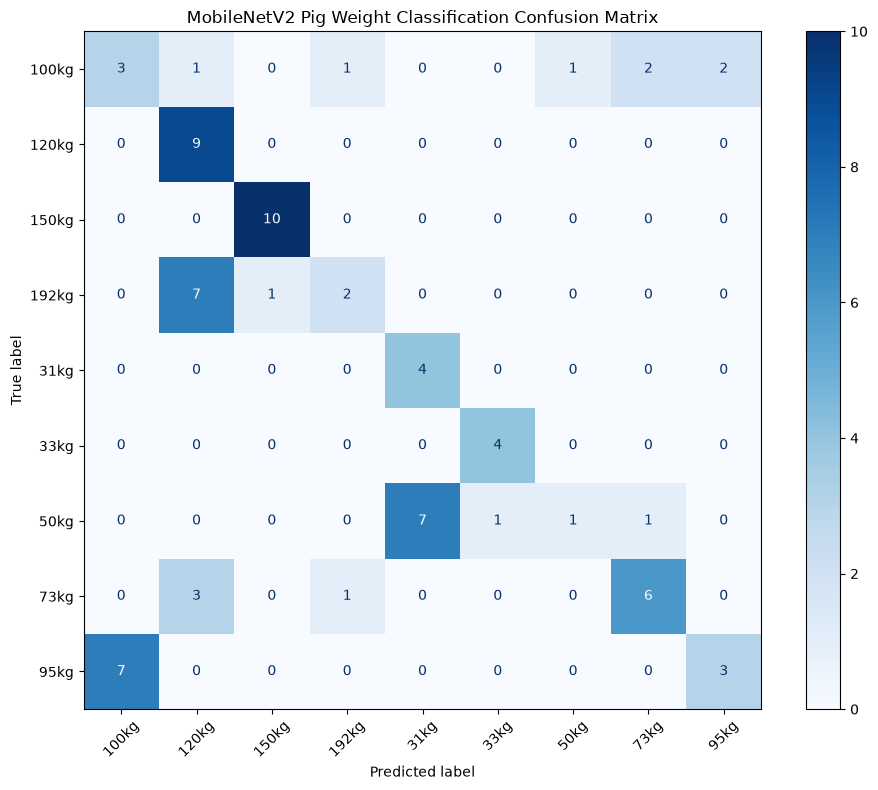

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

# Display the confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)

plt.title("MobileNetV2 Pig Weight Classification Confusion Matrix")
plt.tight_layout()
plt.show()

In [28]:
# Get the pretrained MobileNetV2 base from your trained model
base_model = best_model.get_layer("mobilenetv2_1.00_224")

# Enable fine-tuning
base_model.trainable = True

# Freeze all but the final 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print("Fine-tuning configured successfully!")
print("Total base layers:", len(base_model.layers))
print(
    "Trainable base layers:",
    sum(layer.trainable for layer in base_model.layers)
)

Fine-tuning configured successfully!
Total base layers: 154
Trainable base layers: 19


In [29]:
best_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning!")

Model recompiled for fine-tuning!


In [30]:
FINE_TUNED_PATH = os.path.join(
    MODEL_DIR,
    "pig_weight_model_finetuned.keras"
)

fine_tune_callbacks = [
    keras.callbacks.ModelCheckpoint(
        FINE_TUNED_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

fine_tune_history = best_model.fit(
    train_dataset,
    validation_data=valid_dataset,
    epochs=10,
    class_weight=class_weights,
    callbacks=fine_tune_callbacks
)

Epoch 1/10
38/38 [==============================] - ETA: 0s - loss: 0.7904 - accuracy: 0.7338
Epoch 1: val_loss improved from inf to 1.52343, saving model to d:\CapstonePrototype\smart-pig-farm\ai-service\models\pig_weight_model_finetuned.keras
38/38 [==============================] - 27s 494ms/step - loss: 0.7904 - accuracy: 0.7338 - val_loss: 1.5234 - val_accuracy: 0.4933 - lr: 1.0000e-05
Epoch 2/10
38/38 [==============================] - ETA: 0s - loss: 0.5920 - accuracy: 0.8003
Epoch 2: val_loss improved from 1.52343 to 1.42017, saving model to d:\CapstonePrototype\smart-pig-farm\ai-service\models\pig_weight_model_finetuned.keras
38/38 [==============================] - 20s 495ms/step - loss: 0.5920 - accuracy: 0.8003 - val_loss: 1.4202 - val_accuracy: 0.5600 - lr: 1.0000e-05
Epoch 3/10
38/38 [==============================] - ETA: 0s - loss: 0.4945 - accuracy: 0.8369
Epoch 3: val_loss improved from 1.42017 to 1.41622, saving model to d:\CapstonePrototype\smart-pig-farm\ai-service

In [31]:
fine_tuned_model = keras.models.load_model(
    FINE_TUNED_PATH,
    compile=False,
    safe_mode=False
)

print("Fine-tuned model loaded successfully!")

Fine-tuned model loaded successfully!


In [33]:
fine_tuned_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuned model compiled successfully!")

Fine-tuned model compiled successfully!


In [34]:
fine_tuned_loss, fine_tuned_accuracy = fine_tuned_model.evaluate(
    test_dataset
)

print("\nFINE-TUNED MOBILENETV2 RESULTS")
print(f"Test Loss: {fine_tuned_loss:.4f}")
print(f"Test Accuracy: {fine_tuned_accuracy * 100:.2f}%")

print("\nORIGINAL MODEL ACCURACY: 54.55%")
print(
    f"Accuracy Difference: "
    f"{(fine_tuned_accuracy - 0.5455) * 100:+.2f}%"
)

5/5 [==============================] - 4s 276ms/step - loss: 0.9861 - accuracy: 0.6623

FINE-TUNED MOBILENETV2 RESULTS
Test Loss: 0.9861
Test Accuracy: 66.23%

ORIGINAL MODEL ACCURACY: 54.55%
Accuracy Difference: +11.68%


1/1 [==============================] - 0s 86ms/step


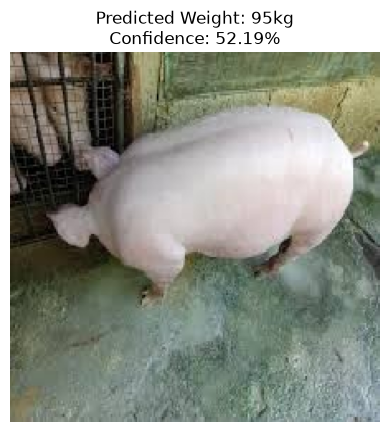

Predicted Weight Category: 95kg
Confidence: 52.19%


In [36]:
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

# Enter the path of your uploaded image
IMAGE_PATH = r"D:\CapstonePrototype\smart-pig-farm\test-pig1.jpg"

# Load and resize image
img = load_img(IMAGE_PATH, target_size=(224, 224))
img_array = img_to_array(img)

# Prepare image for prediction
img_array = np.expand_dims(img_array, axis=0)

# Predict using fine-tuned model
predictions = fine_tuned_model.predict(img_array)

# Get predicted category
predicted_index = np.argmax(predictions[0])
predicted_class = class_names[predicted_index]
confidence = predictions[0][predicted_index] * 100

# Display image and result
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Predicted Weight: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

print("Predicted Weight Category:", predicted_class)
print(f"Confidence: {confidence:.2f}%")